# Diagnostic Breast Cancer Using ML

In [19]:
# Cell 1 — Import libraries and set output folder
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    silhouette_score, roc_curve
)

OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output folder:", OUTPUT_DIR)

Output folder: /kaggle/working/outputs


In [20]:
# Cell 2 — Data acquisition
# Public dataset supplied by Scikit-learn.
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (569, 31)
Columns: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [21]:
# Cell 3 — Prepare target and feature matrix
feature_names = list(data.feature_names)

df["diagnosis"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})
df = df.drop(columns=["target"])

X = df[feature_names].copy()

# Use 1 for malignant for the supervised risk-oriented metrics.
y = (df["diagnosis"] == "Malignant").astype(int)

print("Features:", X.shape)
print(df["diagnosis"].value_counts())

Features: (569, 30)
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [22]:
# Cell 4 — Data quality checks
print("Missing values:")
print(X.isna().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(X.dtypes.value_counts())

print("\nSummary statistics:")
display(X.describe().T)

Missing values:
0

Duplicate rows: 0

Data types:
float64    30
Name: count, dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


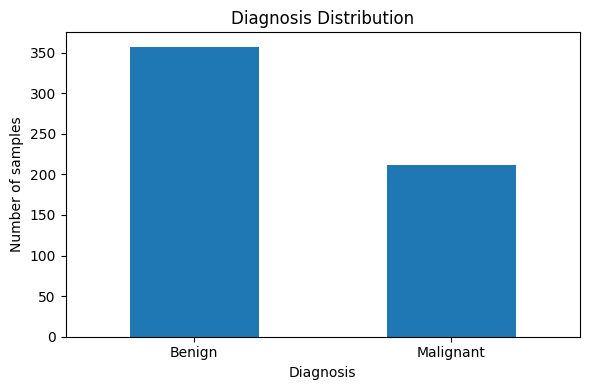

In [23]:
# Cell 5 — Class distribution visualization
counts = df["diagnosis"].value_counts().reindex(["Benign", "Malignant"])

plt.figure(figsize=(6,4))
counts.plot(kind="bar")
plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

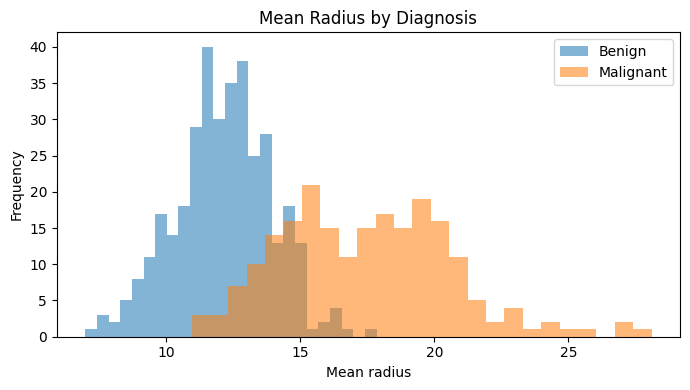

In [24]:
# Cell 6 — Exploratory feature analysis
plt.figure(figsize=(7,4))
for label in ["Benign", "Malignant"]:
    plt.hist(
        X.loc[df["diagnosis"] == label, "mean radius"],
        bins=25, alpha=0.55, label=label
    )
plt.title("Mean Radius by Diagnosis")
plt.xlabel("Mean radius")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

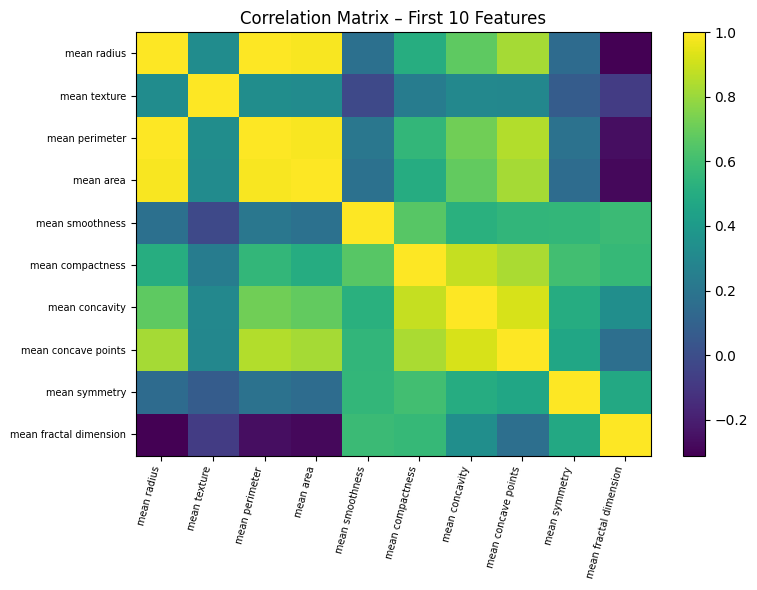

In [25]:
# Cell 7 — Correlation analysis
corr = X.iloc[:, :10].corr()

plt.figure(figsize=(8,6))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(10), corr.columns, rotation=75, ha="right", fontsize=7)
plt.yticks(range(10), corr.index, fontsize=7)
plt.title("Correlation Matrix – First 10 Features")
plt.tight_layout()
plt.show()

In [26]:
# Cell 8 — Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (455, 30)
Testing : (114, 30)


In [27]:
# Cell 9 — Supervised preprocessing pipelines
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

print("Pipelines created.")

Pipelines created.


In [28]:
# Cell 10 — Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in [
    ("Logistic Regression", logreg),
    ("Random Forest", rf)
]:
    print("\n", name)
    for metric in ["accuracy", "f1", "roc_auc"]:
        scores = cross_val_score(
            model, X_train, y_train,
            cv=cv, scoring=metric
        )
        print(
            metric,
            "mean =", round(scores.mean(), 4),
            "std =", round(scores.std(), 4)
        )


 Logistic Regression
accuracy mean = 0.9736 std = 0.0149
f1 mean = 0.964 std = 0.0207
roc_auc mean = 0.9958 std = 0.0047

 Random Forest
accuracy mean = 0.9626 std = 0.0149
f1 mean = 0.9496 std = 0.0207
roc_auc mean = 0.9892 std = 0.0055


In [29]:
# Cell 11 — Train supervised models
logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)

log_pred = logreg.predict(X_test)
rf_pred = rf.predict(X_test)

log_prob = logreg.predict_proba(X_test)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]

In [30]:
# Cell 12 — Evaluate supervised models
def evaluate_model(y_true, pred, prob):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }

log_metrics = evaluate_model(y_test, log_pred, log_prob)
rf_metrics = evaluate_model(y_test, rf_pred, rf_prob)

test_metrics = pd.DataFrame(
    [log_metrics, rf_metrics],
    index=["Logistic Regression", "Random Forest"]
)
display(test_metrics.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.9649,0.975,0.9286,0.9512,0.996
Random Forest,0.9649,0.975,0.9286,0.9512,0.997


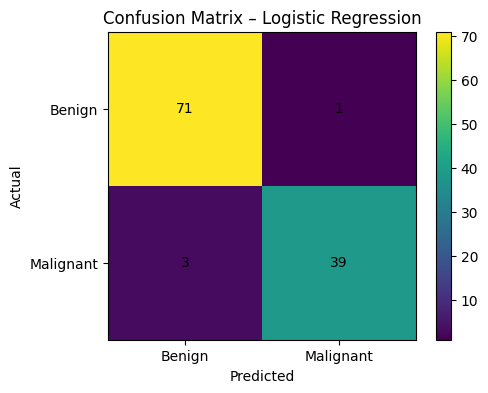

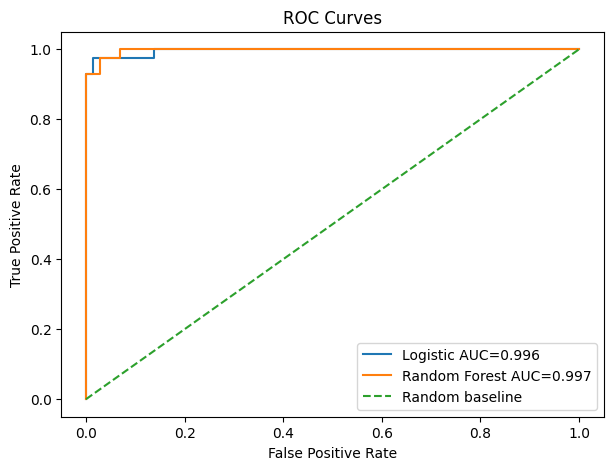

In [31]:
# Cell 13 — Confusion matrix and ROC curves
cm = confusion_matrix(y_test, log_pred)

plt.figure(figsize=(5,4))
plt.imshow(cm)
plt.colorbar()
plt.title("Confusion Matrix – Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ["Benign","Malignant"])
plt.yticks([0,1], ["Benign","Malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha="center", va="center")
plt.show()

fpr1, tpr1, _ = roc_curve(y_test, log_prob)
fpr2, tpr2, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr1, tpr1, label=f"Logistic AUC={log_metrics['ROC-AUC']:.3f}")
plt.plot(fpr2, tpr2, label=f"Random Forest AUC={rf_metrics['ROC-AUC']:.3f}")
plt.plot([0,1], [0,1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [32]:
# Cell 14 — Unsupervised preprocessing and K-Means
# K-Means is fit on standardized features.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cluster_results = []
for k in range(2, 7):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = km.fit_predict(X_scaled)
    cluster_results.append([
        k,
        silhouette_score(X_scaled, labels),
        km.inertia_
    ])

cluster_eval = pd.DataFrame(
    cluster_results,
    columns=["k", "Silhouette", "Inertia"]
)

display(cluster_eval.round(4))

,k,Silhouette,Inertia
0,2,0.3450,11595.4615
1,3,0.3144,10061.7978
2,4,0.2803,9257.3625
3,5,0.1585,8557.7275
4,6,0.1604,7970.2638


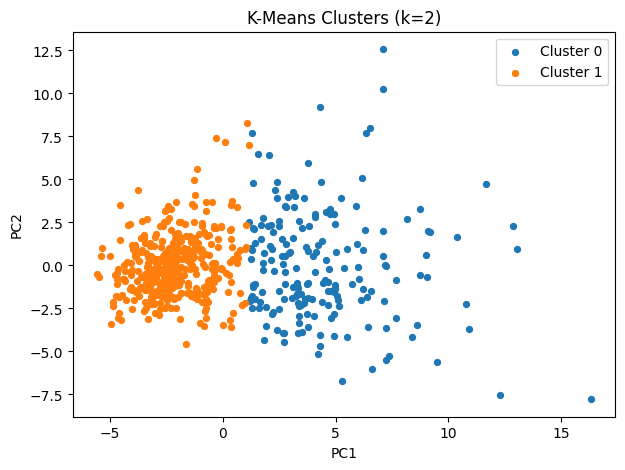

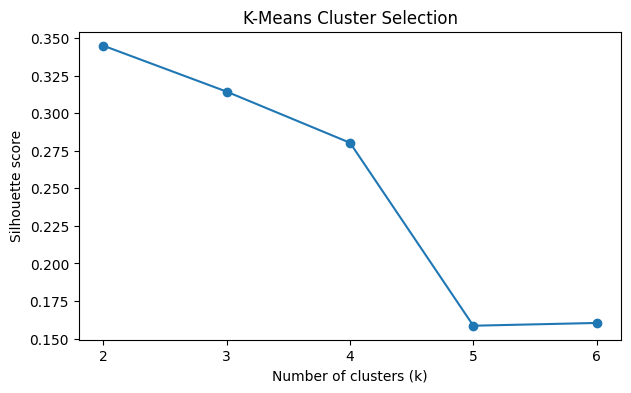

In [33]:
# Cell 15 — Select cluster count and visualize clusters
best_k = int(
    cluster_eval.loc[
        cluster_eval["Silhouette"].idxmax(), "k"
    ]
)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)
clusters = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
for c in range(best_k):
    mask = clusters == c
    plt.scatter(
        X_pca[mask,0],
        X_pca[mask,1],
        s=18,
        label=f"Cluster {c}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"K-Means Clusters (k={best_k})")
plt.legend()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(
    cluster_eval["k"],
    cluster_eval["Silhouette"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-Means Cluster Selection")
plt.xticks(cluster_eval["k"])
plt.show()

In [34]:
# Cell 16 — Analyze cluster characteristics
cluster_diagnosis = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    df["diagnosis"],
    normalize="index"
) * 100

print("Diagnosis composition by cluster (%):")
display(cluster_diagnosis.round(2))

cluster_profile = pd.DataFrame(
    X_scaled,
    columns=feature_names
)
cluster_profile["Cluster"] = clusters

print("Standardized feature profile by cluster:")
display(cluster_profile.groupby("Cluster").mean().round(2))

Diagnosis composition by cluster (%):


diagnosis,Benign,Malignant
Cluster,,
0,7.41,92.59
1,90.26,9.74


Standardized feature profile by cluster:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.97,0.48,1.01,0.96,0.61,1.02,1.14,1.16,0.61,0.25,...,1.04,0.51,1.07,1.0,0.61,0.95,1.04,1.15,0.6,0.62
1,-0.48,-0.24,-0.50,-0.48,-0.30,-0.51,-0.57,-0.58,-0.30,-0.13,...,-0.52,-0.25,-0.53,-0.5,-0.30,-0.47,-0.52,-0.57,-0.3,-0.31


In [35]:
# Cell 17 — Save outputs
test_metrics.to_csv(
    OUTPUT_DIR + "/supervised_test_metrics.csv"
)
cluster_eval.to_csv(
    OUTPUT_DIR + "/kmeans_selection.csv",
    index=False
)
cluster_diagnosis.to_csv(
    OUTPUT_DIR + "/cluster_diagnosis_percent.csv"
)

pd.DataFrame({
    "Actual": y_test,
    "Logistic_Prediction": log_pred,
    "RandomForest_Prediction": rf_pred
}).to_csv(
    OUTPUT_DIR + "/test_predictions.csv",
    index=False
)

print("All important results saved to:", OUTPUT_DIR)

All important results saved to: /kaggle/working/outputs


In [36]:
# Cell 18 — Final model report
print("=== SUPERVISED LEARNING ===")
display(test_metrics.round(4))

print("\n=== UNSUPERVISED LEARNING ===")
print("Selected k:", best_k)
print("Best silhouette:",
      round(cluster_eval["Silhouette"].max(), 4))

print("\n=== CLASSIFICATION REPORT: LOGISTIC REGRESSION ===")
print(
    classification_report(
        y_test,
        log_pred,
        target_names=["Benign", "Malignant"],
        digits=4
    )
)

=== SUPERVISED LEARNING ===


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.9649,0.975,0.9286,0.9512,0.996
Random Forest,0.9649,0.975,0.9286,0.9512,0.997



=== UNSUPERVISED LEARNING ===
Selected k: 2
Best silhouette: 0.345

=== CLASSIFICATION REPORT: LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

      Benign     0.9595    0.9861    0.9726        72
   Malignant     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114

